# COMP3602 · Week 4 Lab — Investigating Student Learning Data
**From messy records to reliable insights** · 90 minutes · Beginner–intermediate

**Scenario:** The university wants to examine student learning habits, exam performance, and attendance. You have two CSV files that contain deliberate data-quality problems. Investigate before changing anything.

**Files:** `student_learning.csv`, `student_attendance.csv` (place in the same folder as this notebook).

**Objectives:** Identify and justify cleaning decisions; detect outliers using IQR and Z-score; inspect noisy numerical data visually; merge two sources; use Week 3 frequency distributions and charts; use Week 2 simple random sampling.

**Important:** An unusual value is not automatically wrong. Write short explanations alongside your code. Use simple Pandas and Matplotlib commands.

**Data dictionary**

| Column | Meaning / expected range |
|---|---|
| Student_ID | Student identifier; one record per student expected |
| Age | Years; normally 18–25 |
| Program | CS, AI, IT, DS (equivalent full names may appear) |
| City | Muscat, Seeb, Sohar, Nizwa |
| Study_Hours | Average **daily** study hours; most students expected near 1–10 |
| Screen_Time | Average daily **recreational** screen hours; measurements can naturally vary |
| Exam_Score | Exam mark, 0–100 |
| StudentNo | Student identifier in the attendance file |
| Attendance | Attendance percentage, 0–100 |

**Guidance:** Complete the code cells and answer the written questions. The tasks deliberately mix topics rather than following lecture order.

## Setup — Load both CSV files

In [9]:
# === Write your answer here: ===
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv('student_learning.csv')
attendance = pd.read_csv('student_attendance.csv')


students.head(10)


,Student_ID,Age,Program,City,Study_Hours,Screen_Time,Exam_Score
0,S101,24.0,CS,Muscat,4.9,6.0,73.0
1,S102,18.0,AI,Nizwa,3.8,5.0,56.0
2,S103,19.0,IT,muscat,3.4,5.5,55.0
3,S104,21.0,DS,Seeb,2.0,7.4,50.0
4,S105,NaN,CS,Muscat,4.6,5.2,70.0
5,S106,24.0,cs,Nizwa,3.2,6.7,59.0
6,S107,21.0,IT,Sohar,2.3,5.4,59.0
7,S108,24.0,DS,Sohar,7.5,3.5,87.0
8,S109,18.0,CS,Seeb,3.4,5.6,52.0
9,S110,24.0,AI,Muscat,3.1,5.0,76.0


## Investigation 1 — Count students in each academic program
1. Check the number of rows, missing values, and duplicate rows. 2. Display the raw frequency of each `Program` category and draw a bar chart. 3. Explain why the first bar chart may be misleading and what must be standardized.

**Hint:** `shape`, `isnull().sum()`, `duplicated().sum()`, `value_counts()`, `plot(kind="bar")`.

**Explain:** Do differently written labels necessarily represent different programs?

Shape of the dataset: (82, 7)
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   82 non-null     str    
 1   Age          79 non-null     float64
 2   Program      82 non-null     str    
 3   City         80 non-null     str    
 4   Study_Hours  82 non-null     float64
 5   Screen_Time  82 non-null     float64
 6   Exam_Score   80 non-null     float64
dtypes: float64(4), str(3)
memory usage: 4.6 KB
Missing values in each column:
Student_ID     0
Age            3
Program        0
City           2
Study_Hours    0
Screen_Time    0
Exam_Score     2
dtype: int64
Number of duplicate rows:
2
Number of students in each program:
Program
CS                         21
DS                         21
IT                         20
AI                         12
cs                          1
Computer Science            1
ai               

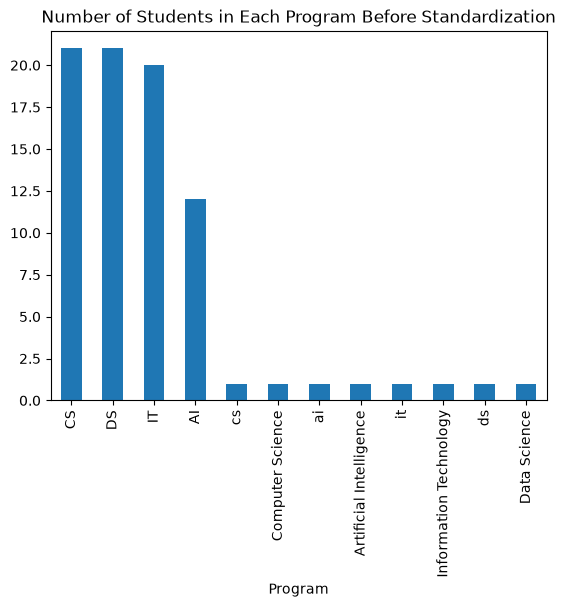

Number of students in each program after standardization:
Program
CS    23
DS    23
IT    22
AI    14
Name: count, dtype: int64


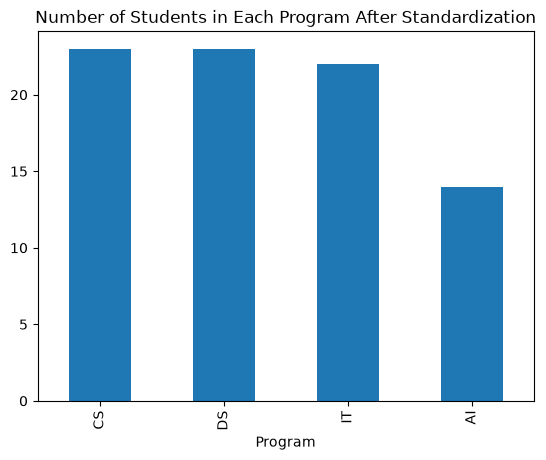

In [10]:
# === Write your answer here: ===
print("Shape of the dataset:", students.shape)
print("Dataset information:")
students.info()
print("Missing values in each column:")
print(students.isnull().sum())
print("Number of duplicate rows:")
print(students.duplicated().sum())
print("Number of students in each program:")
print(students["Program"].value_counts(dropna=False))
students["Program"].value_counts(dropna=False).plot(kind='bar', title='Number of Students in Each Program Before Standardization')
plt.show()


students["Program"] = students["Program"].replace({
    "Data Science": "DS",
    "ds": "DS",
    "Computer Science": "CS",
    "cs": "CS",
    "Artificial Intelligence": "AI",
    "ai": "AI",
    "Information Technology": "IT",
    "it": "IT"
})

print("Number of students in each program after standardization:")
print(students["Program"].value_counts(dropna=False))
students["Program"].value_counts(dropna=False).plot(kind='bar', title='Number of Students in Each Program After Standardization')
plt.show()

# Explain: No. value_counts() compares text literally, so differences in case, spaces, or abbreviations (e.g., "Data Science", "ds", "DS") create separate categories for the same program.
# The first chart is misleading because one program's students are split across several bars, so programs look smaller and more numerous than they are.
# Standardize: letter case, extra spaces, and full names vs. abbreviations.


## Investigation 2 — Identify unusual daily study-hour values
1. Draw a box plot of `Study_Hours`. 2. Calculate Q1, Q3, IQR, and the lower/upper fences. 3. Display records flagged by IQR. 4. Calculate Z-scores using the **population standard deviation** (`ddof=0`), and display records with `|z| > 3`. 5. Compare the two methods. **Do not delete flagged rows.**

**Hint:** Use `quantile(0.25)`, `quantile(0.75)`, `mean()`, `std(ddof=0)`, and Boolean filtering. Work on the original data before making corrections.

**Explain:** Are IQR and Z-score guaranteed to flag identical records? Why not?

C:\Users\ibnHi\AppData\Local\Temp\ipykernel_20444\1031622628.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(students["Study_Hours"], vert=False)


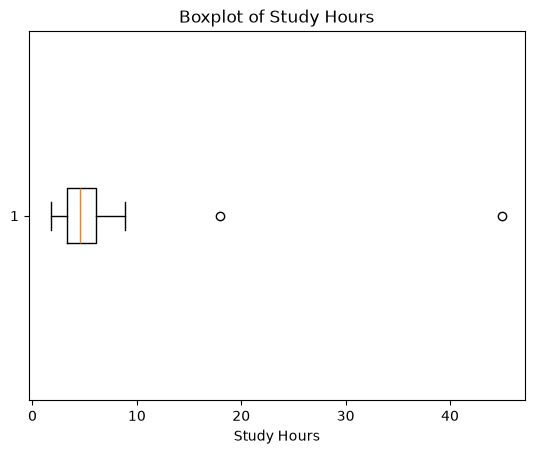


Q1: 3.3
Q3: 6.1
IQR: 2.8

Lower Bound: -0.8999999999999995
Upper Bound: 10.299999999999999

Outliers in Study Hours:
   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0
73       S173  25.0      CS  Sohar         18.0          6.3        42.0

Z-score of Study Hours:
0    -0.091443
1    -0.316190
2    -0.397916
3    -0.683957
4    -0.152738
        ...   
77    0.153735
78   -0.132306
79    0.398913
80   -0.295758
81   -0.214032
Name: Study_Hours, Length: 82, dtype: float64

Outliers based on Z-score:
   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0

IQR flagged: 2 | Z-score flagged: 1


In [11]:
# === Write your answer here: ===
plt.boxplot(students["Study_Hours"], vert=False)
plt.title("Boxplot of Study Hours")
plt.xlabel("Study Hours")
plt.show()
print()
q1 = students["Study_Hours"].quantile(0.25)
q3 = students["Study_Hours"].quantile(0.75)
iqr = q3 - q1
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

print()
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print()
print("Outliers in Study Hours:")
outliers = students[(students["Study_Hours"] < lower_bound) | (students["Study_Hours"] > upper_bound)]
print(outliers)
print()

z_score = (students["Study_Hours"] - students["Study_Hours"].mean()) / students["Study_Hours"].std(ddof=0)
print("Z-score of Study Hours:")
print(z_score)

outliers_z = students[abs(z_score) > 3]
print()
print("Outliers based on Z-score:")
print(outliers_z)

print()
print("IQR flagged:", len(outliers), "| Z-score flagged:", len(outliers_z))
# Explain: No. IQR uses quartiles, which are resistant to extreme values, while Z-score uses the mean and standard deviation, which are inflated by the outliers themselves (masking).
# The thresholds also differ (1.5*IQR vs |z| > 3), so IQR usually flags more records, and the two methods are not guaranteed to flag the same ones.

### Verification note — provided by the university data team
The record for **S140** contains a confirmed typing error: `Study_Hours = 45.0` should be **4.5**. The unusually high study-hours value for **S173** has **not** been verified and must **not** be automatically replaced or deleted. Keep it in the data and document the concern.

**Decision:** Correct only the verified error. Keep the unverified value and consider its effect when interpreting charts.

## Investigation 3 — Produce a consistent student dataset
1. Remove exact duplicate rows. 2. Correct the **verified** study-hours error using `Student_ID`. 3. Replace missing ages with the median; replace missing cities with `Unknown`; for this exercise, exclude records with missing `Exam_Score` from subsequent exam-score analysis. 4. Standardize program and city labels. 5. Verify missing counts, duplicate counts, and program frequencies.

**Hint:** Use `drop_duplicates()`, `loc[]`, `fillna()`, `dropna(subset=...)`, `replace()`, and `str.title()`. Do not change S173.

**Explain:** Which cleaning steps change the number of records, and which only change values?

In [12]:
before = len(students)
students = students.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", before - len(students))

students.loc[students["Student_ID"] == "S140", "Study_Hours"] = 4.5

students["Age"] = students["Age"].fillna(students["Age"].median())
students["City"] = students["City"].fillna("Unknown")

#program already standardized, so no need to standardize again
students["City"] = students["City"].str.strip().str.title()

students = students.dropna(subset=["Exam_Score"]).reset_index(drop=True)

print("Missing values:\n", students.isnull().sum())
print("Duplicate rows:", students.duplicated().sum())
print(students["Program"].value_counts(dropna=False))
print(students["City"].value_counts(dropna=False))
print("Remaining rows:", len(students))

# Explain: Steps that change the number of records: drop_duplicates() and dropna(subset=["Exam_Score"]), because they remove rows.
# Steps that only change values: correcting S140, fillna() for Age and City, and standardizing labels (replace, str.title), because the row count stays the same.
# Note: S173's Study_Hours is unverified, so it was kept unchanged in the data; its possible influence on charts and averages should be considered when interpreting results.

Duplicate rows removed: 2
Missing values:
 Student_ID     0
Age            0
Program        0
City           0
Study_Hours    0
Screen_Time    0
Exam_Score     0
dtype: int64
Duplicate rows: 0
Program
CS    22
IT    22
DS    20
AI    14
Name: count, dtype: int64
City
Sohar      22
Muscat     21
Nizwa      17
Seeb       16
Unknown     2
Name: count, dtype: int64
Remaining rows: 78


## Investigation 4 — Combine attendance with the cleaned records
1. Inspect `student_attendance.csv`. 2. Rename `StudentNo` to `Student_ID`. 3. Merge it with the cleaned student data on that identifier, using an **inner** join. 4. Check the row count and missing values after merging.

**Hint:** Use `rename(columns={...})`, `pd.merge(..., on="Student_ID", how="inner")`.

**Explain:** Why is checking the row count after a merge important?

In [13]:
# === Write your answer here: ===
attendance = attendance.rename(
    columns={"StudentNo": "Student_ID"}
)
print(attendance.head())
print("students rows:", len(students), "| attendance rows:", len(attendance))
df = pd.merge(
    students,
    attendance,
    on="Student_ID",
    how="inner"
)

print(df.head())
print("Shape of the merged dataset:", df.shape)
print("Missing values in the merged dataset:\n", df.isnull().sum())
#Explain: Because a merge can silently drop unmatched records or duplicate rows (from repeated or mismatched IDs), and comparing the row count with the original tables is how we catch that before it distorts later analysis.

  Student_ID  Attendance
0       S101          65
1       S102          71
2       S103          73
3       S104          72
4       S105          73
students rows: 78 | attendance rows: 80
  Student_ID   Age Program    City  Study_Hours  Screen_Time  Exam_Score  \
0       S101  24.0      CS  Muscat          4.9          6.0        73.0   
1       S102  18.0      AI   Nizwa          3.8          5.0        56.0   
2       S103  19.0      IT  Muscat          3.4          5.5        55.0   
3       S104  21.0      DS    Seeb          2.0          7.4        50.0   
4       S105  22.0      CS  Muscat          4.6          5.2        70.0   

   Attendance  
0          65  
1          71  
2          73  
3          72  
4          73  
Shape of the merged dataset: (78, 8)
Missing values in the merged dataset:
 Student_ID     0
Age            0
Program        0
City           0
Study_Hours    0
Screen_Time    0
Exam_Score     0
Attendance     0
dtype: int64


## Investigation 5 — Summarize the distribution of exam scores
1. Create a grouped frequency table with intervals **[0, 40), [40, 50), …, [90, 101)**. 2. Add a cumulative-frequency column. 3. Draw a histogram using the same bin boundaries. 4. Interpret which score range has the highest frequency. **Optional:** draw an ogive using cumulative frequencies.

**Hint:** Use `pd.cut()`, `value_counts(sort=False)`, `cumsum()`, and `plot(kind="hist", bins=...)`. The final upper boundary is 101 to include a score of 100.

**Explain:** What does cumulative frequency tell us that ordinary frequency does not?

            Frequency  Cumulative Frequency
Exam_Score                                 
[0, 40)             1                     1
[40, 50)            3                     4
[50, 60)           27                    31
[60, 70)           20                    51
[70, 80)           18                    69
[80, 90)            8                    77
[90, 101)           1                    78


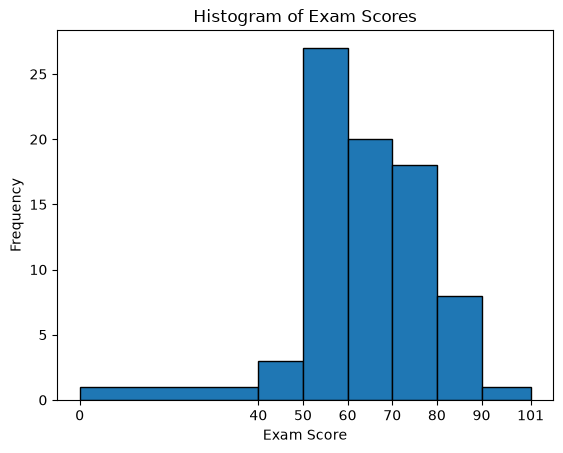

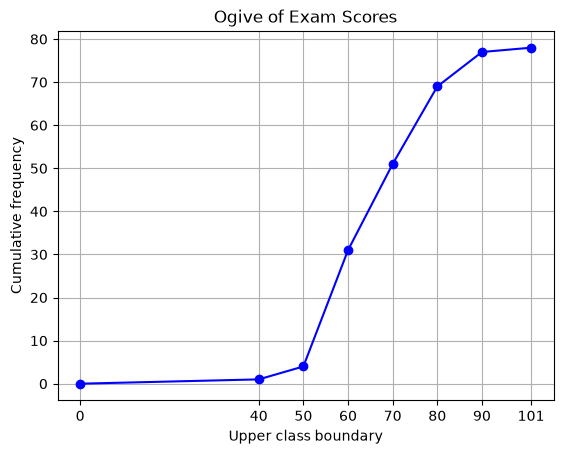

Highest frequency range: [50, 60) with 27 students


In [14]:
bins = [0, 40, 50, 60, 70, 80, 90, 101]

score_groups = pd.cut(df["Exam_Score"], bins=bins, right=False)
freq = score_groups.value_counts(sort=False)

freq_table = pd.DataFrame({"Frequency": freq, "Cumulative Frequency": freq.cumsum()})
print(freq_table)

df["Exam_Score"].plot(kind="hist", bins=bins, edgecolor="black", title="Histogram of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.xticks(bins)
plt.show()

plt.plot([bins[0]] + bins[1:], [0] + list(freq.cumsum()), marker="o", color="b")
plt.title("Ogive of Exam Scores")
plt.xlabel("Upper class boundary")
plt.ylabel("Cumulative frequency")
plt.xticks(bins)
plt.grid()
plt.show()

print("Highest frequency range:", freq.idxmax(), "with", freq.max(), "students")

# Interpretation: The highest frequency is in [50, 60) with 27 students. Most scores (65 of 78 students) fall between 50 and 80, with a few low scores (4 students below 50) and only one score of 90 or above, so the distribution is concentrated in the middle with a short tail toward lower scores.
# Explain: Frequency shows how many students fall in each interval alone, while cumulative frequency shows how many students scored below a given boundary (e.g., how many scored under 60), which helps find proportions below a cutoff and approximate the median and percentiles. The last cumulative value equals the total number of students.

## Investigation 6 — Compare a random sample with the cleaned dataset
1. Draw a **simple random sample of 20 students** from the merged data using `random_state=42`. 2. Calculate mean exam score for the sample and the full merged dataset. 3. Compare them. 4. Explain whether one sample is guaranteed to have exactly the same mean as the full dataset.

**Hint:** Use `sample(n=20, random_state=42)` and `mean()`.

**Explain:** Does simple random sampling guarantee a representative sample in every draw?

In [15]:
sample = df.sample(n=20, random_state=42)

sample_mean = sample["Exam_Score"].mean()
full_mean = df["Exam_Score"].mean()

print("Sample mean of Exam Scores:", sample_mean)
print("Full dataset mean of Exam Scores:", full_mean)
print("Difference between sample mean and full mean:", abs(sample_mean - full_mean))

# Comparison: The sample mean (68.65) is higher than the full dataset mean (64.86) by about 3.79 points, so the sample is close but not identical to the full data.
# Explain: No. A sample of 20 is a small random part of the data, so its mean varies from draw to draw (sampling error) and is not guaranteed to equal the full mean.
# Simple random sampling gives every student an equal chance of selection and is unbiased in the long run, but it does not guarantee a representative sample in every draw; a single draw may over- or under-represent some programs, cities, or score levels, and the risk shrinks as the sample size grows.

Sample mean of Exam Scores: 68.65
Full dataset mean of Exam Scores: 64.85897435897436
Difference between sample mean and full mean: 3.791025641025641


## Investigation 7 — Make two charts and interpret them responsibly
1. Create a **bar chart** of the cleaned program counts. 2. Draw a **scatter plot** of study hours against exam score. 3. Inspect the distribution of `Screen_Time` using a histogram and describe its natural variation; **do not smooth or replace values**. 4. Explain how the unverified high study-hours observation could influence the scatter plot. 5. Save the prepared dataset as `student_learning_prepared.csv`.

**Hint:** Use `value_counts().plot(kind="bar")`, `plot(kind="scatter")`, `plot(kind="hist")`, and `to_csv(index=False)`.

**Explain:** Does an unusual value automatically indicate measurement noise? What information would you need before changing it?

In [16]:
# Screen_Time: Roughly symmetric, peaking at 5-5.5 hours, with most values between 4 and 7 and no extreme outliers. This is natural variation, so values were not smoothed or replaced.
# S173: Its unverified Study_Hours (about 18) was kept. It sits far right in the scatter plot with a low score (about 42), stretching the x-axis and pulling the trend downward, so conclusions should account for it.
# Explain: No. An unusual value may be genuine or an entry error. Before changing it we need confirmation from the data owner, the plausible range and unit, the correct value, and a documented reason.

## Final reflection (write 3–5 sentences)

1. Which two preprocessing decisions mattered most for reliable analysis?
2. How did Week 3 visualization help you detect or understand a problem?
3. What did the Week 2 random sample show you about variation between a sample and the full dataset?

**Reminder:** Good data analysis requires both correct Python operations and defensible decisions.

**1.** The two most important decisions were correcting only the verified S140 error while keeping the unverified S173 value, and standardizing the Program labels before counting.
These protected the data from a confirmed typing error and an unjustified edit, and stopped one program from being split across several categories.

**2.** The first bar chart showed fragmented program counts that exposed the label problem.
The scatter plot showed S173 (about 18 study hours) as an isolated point that stretches the axis and pulls the trend downward.

**3.** The random sample (n = 20) had a mean of 68.65 against 64.86 for the full dataset, a difference of about 3.79 points.
This showed that a sample is close to the full data but not identical, because of sampling error.